In [1]:
import numpy as np
from scipy.optimize import curve_fit
import h5py

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter
from matplotlib import gridspec

import delayscan
import delayscan.kineticmodels as km
from delayscan.retrieve import multiple_gaussians

In [2]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Default mpl colour tablet
colors = list(mcolors.TABLEAU_COLORS)

#Extra colours
violet = '#5D3FD3'
red = '#D62828'

blue ='#3A86FF'
green='#6A994E'

In [3]:
CROSS_CORRELATION = 0.320 #ps cross-correlation with 250 & 267
SIGMA = CROSS_CORRELATION / 2.355 

### Load data

In [4]:
# Load data to fit
loaddata = np.loadtxt("data/out/subtractedspectra.csv",delimiter=',')

energies_rebinned = loaddata[0,1:]
delays = loaddata[1:,0]
subtracted_rebinned = loaddata [1:,1:]

### Flatten data for global fit

In [5]:
# Must process data to fit only the relevant data
# Must also flatten the data so that we can fit it with scipy's curve_fit 

In [6]:
# Select data below 2.2 eV as above it is ~0
# and it would skew the fits with noise
mask = energies_rebinned<2.2
traces = subtracted_rebinned[:,mask]

# Normalise traces by max counts so that we get nice numbers
traces /= np.amax(traces)

traces.shape

(47, 70)

In [7]:
# Tile delays
flat_delays = np.tile(delays,(traces.shape[1]))
#Flatten traces
flat_traces = traces.T.flatten()
#Check length
flat_traces.shape,flat_delays.shape

((3290,), (3290,))

### EAS model

In [8]:
# Pick model
EAS_mod = km.EAS_model(0,SIGMA,*traces.shape)

#### Fit

In [9]:
# Pick guess
# First two args are tau1 and tau2
# The rest are A1,A2,A1,A2... (i.e. two amplitudes per energy value)
p0 = [1,3]+[x for n in range(traces.shape[1]) for x in (1,0.5)]

#Fit
params,pcov = curve_fit(EAS_mod.global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))

# Extract results
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]

energies = energies_rebinned[mask]

#Display results
print("Time constants")
print(f"tau1 = {tau1:.4f} ± {tau1_err:.4f} ps")
print(f"tau2 = {tau2:.4f} ± {tau2_err:.4f} ps")

print("Amplitudes")
display(params[2:])



Time constants
tau1 = 0.5500 ± 0.0298 ps
tau2 = 2.8433 ± 0.0261 ps
Amplitudes


array([ 1.30075639e-02, -4.80098026e-04,  1.27705096e-02, -1.96049918e-04,
        1.55431011e-02,  1.63305248e-03,  1.86224457e-02, -3.43946679e-04,
        1.72192306e-02,  2.49443786e-03,  2.35310444e-02,  3.37082362e-03,
        3.14223883e-02,  4.01308246e-03,  3.76340813e-02,  2.33182671e-03,
        5.07513727e-02,  5.19760025e-03,  6.24358847e-02,  1.32967365e-02,
        8.40176225e-02,  1.54140664e-02,  1.05730094e-01,  2.21085373e-02,
        1.30702882e-01,  2.62630758e-02,  1.69423605e-01,  4.43335227e-02,
        2.09554053e-01,  5.76389583e-02,  2.46023974e-01,  7.43929130e-02,
        2.85063908e-01,  9.50162772e-02,  3.31402270e-01,  1.29494037e-01,
        3.80942129e-01,  1.57271901e-01,  4.29539732e-01,  1.83885281e-01,
        4.95694390e-01,  2.02596539e-01,  5.39286809e-01,  2.56125154e-01,
        5.77693663e-01,  3.07125865e-01,  6.39781985e-01,  3.59588627e-01,
        7.06674447e-01,  3.78328041e-01,  7.54763123e-01,  4.24162453e-01,
        7.93128312e-01,  

#### Check fits and residuals

This long plot is a bit annoying but I found it is the best way to see whether the model fit well.

(-1.0, 5.0)

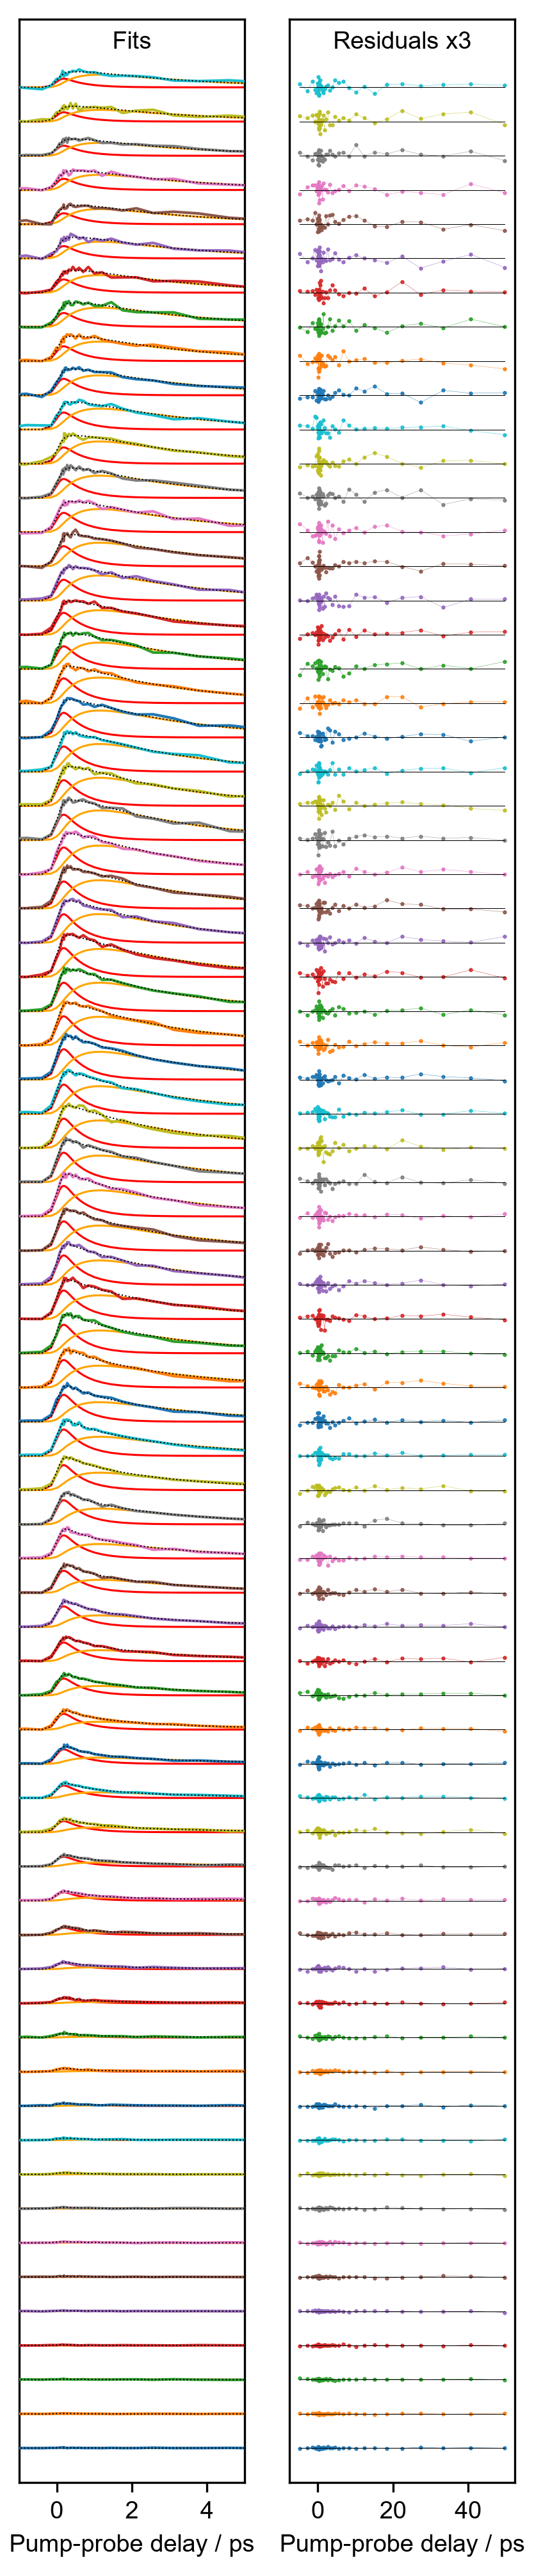

In [10]:
fig, (ax0,ax1) = plt.subplots(1,2,sharey=True)
fig.set_size_inches(ACSwid,ACSwid*5)

OFFSET = 0.75

for n in range(traces.shape[1]):
    # Plot trace
    ax0.plot(delays,traces[:,n] + OFFSET*n,zorder=20)
    # Plot fit
    trace = EAS_mod.kinetic_model(delays,A1s[n],A2s[n],tau1,tau2)
    ax0.plot(delays,trace + OFFSET*n,'k:',zorder=30,lw=.5)
    # Plot residuals (3x as intense)
    ax1.plot(delays,3*(traces[:,n]-trace) + OFFSET*n,'o-',zorder=20,ms=.5,lw=.1)
    # Plot y=0
    ax1.plot(delays,delays*0 + OFFSET*n,'k',zorder=30,lw=.25)
    
    # Plot A component
    trace =  EAS_mod.A_model(delays,A1s[n],tau1,SIGMA)
    ax0.plot(delays,trace + OFFSET*n,'r',lw=.75)
    #Plot B component    
    trace =  EAS_mod.B_model(delays,A2s[n],tau1,tau2,SIGMA)
    ax0.plot(delays,trace + OFFSET*n,'orange',lw=.75)

    
ax0.set_ylim(-OFFSET,(traces.shape[1] + 1)*OFFSET)
ax0.set_yticks([])
for ax in ax0,ax1:
    ax.set_xlabel("Pump-probe delay / ps")
ax0.text(.5,.995,"Fits", va = "top",ha = "center",transform = ax0.transAxes)
ax1.text(.5,.995,"Residuals x3", va = "top",ha = "center",transform = ax1.transAxes)

ax0.set_xlim(-1,5)

### Display spectra

Text(0, 0.5, 'Photoelectron signal / a.u.')

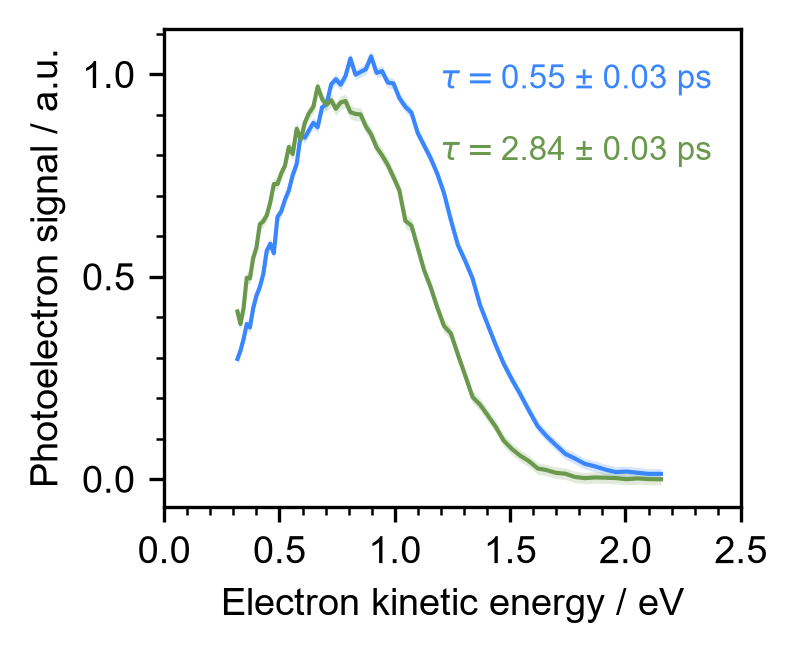

In [11]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]
energies = energies_rebinned[mask]

ax.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=blue,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=green,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
# ax.set_ylim(0,1.2)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")


In [12]:
A1s_EAS = A1s
A2s_EAS = A2s
A1s_err_EAS = A1s_err
A2s_err_EAS = A2s_err

taus_EAS = tau1,tau2
tau_errs_EAS = tau1_err,tau2_err

params_EAS = params

### DAS model

In [13]:
# Pick model
DAS_mod = km.DAS_model(0,SIGMA,*traces.shape)

#### Fit

In [14]:
# Pick guess
# First two args are tau1 and tau2
# The rest are A1,A2,A1,A2... (i.e. two amplitudes per energy value)
p0 = [1,3.5]+[x for n in range(traces.shape[1]) for x in (1, 0.5)]

params,pcov = curve_fit(DAS_mod.global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))

# Extract results
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]

energies = energies_rebinned[mask]

#Display results
print("Time constants")
print(f"tau1 = {tau1:.4f} ± {tau1_err:.4f} ps")
print(f"tau2 = {tau2:.4f} ± {tau2_err:.4f} ps")

print("Amplitudes")
display(params[2:])


Time constants
tau1 = 0.5499 ± 0.0298 ps
tau2 = 2.8433 ± 0.0261 ps
Amplitudes


array([ 1.36031621e-02, -5.95231807e-04,  1.30136165e-02, -2.42885323e-04,
        1.35187136e-02,  2.02472130e-03,  1.90493208e-02, -4.26390191e-04,
        1.41266624e-02,  3.09281799e-03,  1.93517708e-02,  4.17954253e-03,
        2.64468051e-02,  4.97595112e-03,  3.47432919e-02,  2.89143460e-03,
        4.43069471e-02,  6.44496578e-03,  4.59506529e-02,  1.64860475e-02,
        6.49074207e-02,  1.91113669e-02,  7.83201354e-02,  2.74113878e-02,
        9.81415908e-02,  3.25628305e-02,  1.14458520e-01,  5.49669504e-02,
        1.38093173e-01,  7.14633031e-02,  1.53789866e-01,  9.22361645e-02,
        1.67261402e-01,  1.17805066e-01,  1.70852422e-01,  1.60551885e-01,
        1.85954012e-01,  1.94990836e-01,  2.01555557e-01,  2.27986944e-01,
        2.44510725e-01,  2.51186676e-01,  2.21738098e-01,  3.17551523e-01,
        1.96913614e-01,  3.80782459e-01,  1.93957530e-01,  4.45826636e-01,
        2.37616940e-01,  4.69060500e-01,  2.28879069e-01,  5.25886707e-01,
        2.04706691e-01,  

#### Check fits and residuals

This long plot is a bit annoying but I found it is the best way to see whether the model fit well.

(-1.0, 5.0)

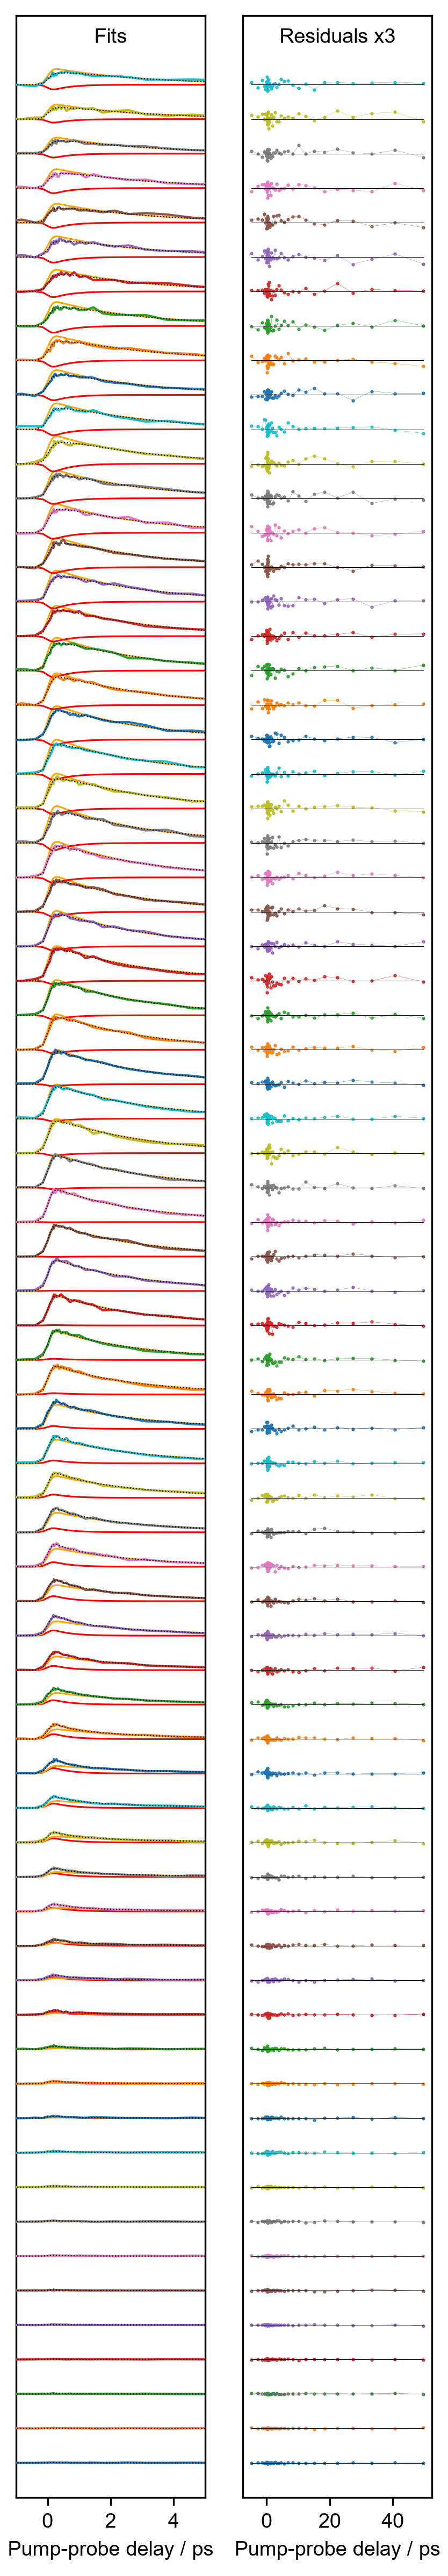

In [15]:
fig, (ax0,ax1) = plt.subplots(1,2,sharey=True)
plt.gcf().set_size_inches(ACSwid,ACSwid*6)

OFFSET = 1

for n in range(traces.shape[1]):
    # Plot trace
    ax0.plot(delays,traces[:,n] + OFFSET*n,zorder=20)
    #Plot fit
    trace = DAS_mod.kinetic_model(delays,A1s[n],A2s[n],tau1,tau2)
    ax0.plot(delays,trace + OFFSET*n,'k:',zorder=30,lw=.5)
    # Plot residuals (3x as intense)
    ax1.plot(delays,3*(traces[:,n]-trace) + OFFSET*n,'o-',zorder=20,ms=.5,lw=.1)
    # Plot y=0
    ax1.plot(delays,delays*0 + OFFSET*n,'k',zorder=30,lw=.25)

    #Plot first decay
    trace =  A1s[n]*km.monoexp(delays,1/tau1,SIGMA)
    ax0.plot(delays,trace+OFFSET*n,'r',lw=.75)
    # Plot second decay
    trace =  A2s[n]*km.monoexp(delays,1/tau2,SIGMA)
    ax0.plot(delays,trace+OFFSET*n,'orange',lw=.75)

    
ax0.set_ylim(-OFFSET,(traces.shape[1] + 1)*OFFSET)
ax0.set_yticks([])
for ax in ax0,ax1:
    ax.set_xlabel("Pump-probe delay / ps")
ax0.text(.5,.995,"Fits", va = "top",ha = "center",transform = ax0.transAxes)
ax1.text(.5,.995,"Residuals x3", va = "top",ha = "center",transform = ax1.transAxes)

ax0.set_xlim(-1,5)

Text(0, 0.5, 'Photoelectron signal / a.u.')

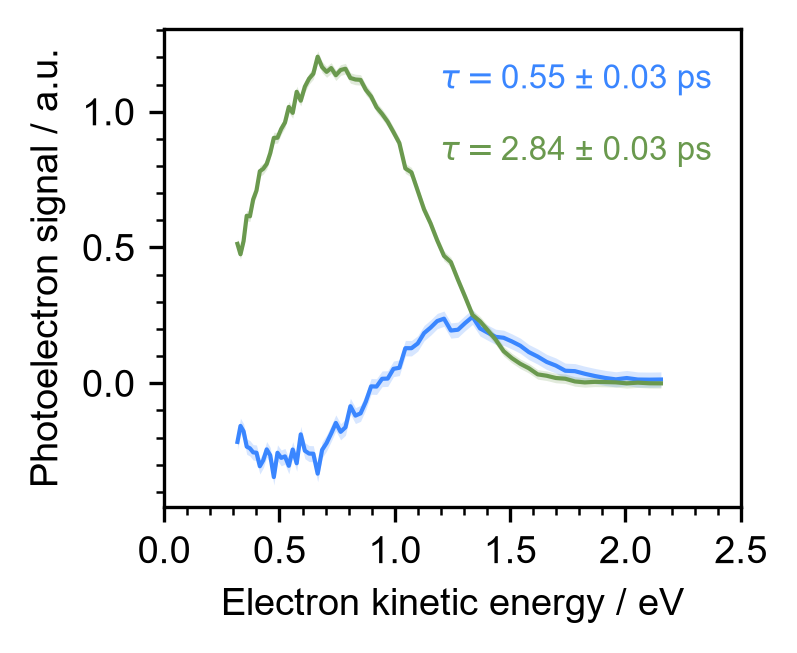

In [16]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)


ax.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=blue,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=green,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

ax.set_xlim(0,2.5)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")


In [17]:
A1s_DAS = A1s
A2s_DAS = A2s
A1s_err_DAS = A1s_err
A2s_err_DAS = A2s_err

taus_DAS = tau1,tau2
tau_errs_DAS = tau1_err,tau2_err

params_DAS = params

### Check EAS <--> DAS conversion

In [18]:
def EAS_to_DAS(A1s_EAS,A2s_EAS,tau1,tau2):
    """Converting EAS to DAS. 
    Both models are just different linear combinations of the same exponentials.
    Therefore, they can be converted into one another"""
    k1, k2 = 1/tau1, 1/tau2
    k_term = k1/(k2-k1)

    A1s_DAS = A1s_EAS + k_term * A2s_EAS
    A2s_DAS = -k_term * A2s_EAS

    return A1s_DAS, A2s_DAS

def DAS_to_EAS(A1s_DAS,A2s_DAS,tau1,tau2):
    """Converting DAS to EAS. 
    Both models are just different linear combinations of the same exponentials.
    Therefore, they can be converted into one another"""
    k1, k2 = 1/tau1, 1/tau2
    k_term = k1/(k2-k1)

    A1s_EAS = A1s_DAS + A2s_DAS
    A2s_EAS = -A2s_DAS / k_term

    return A1s_EAS, A2s_EAS

Text(0, 0.5, 'Photoelectron signal / a.u.')

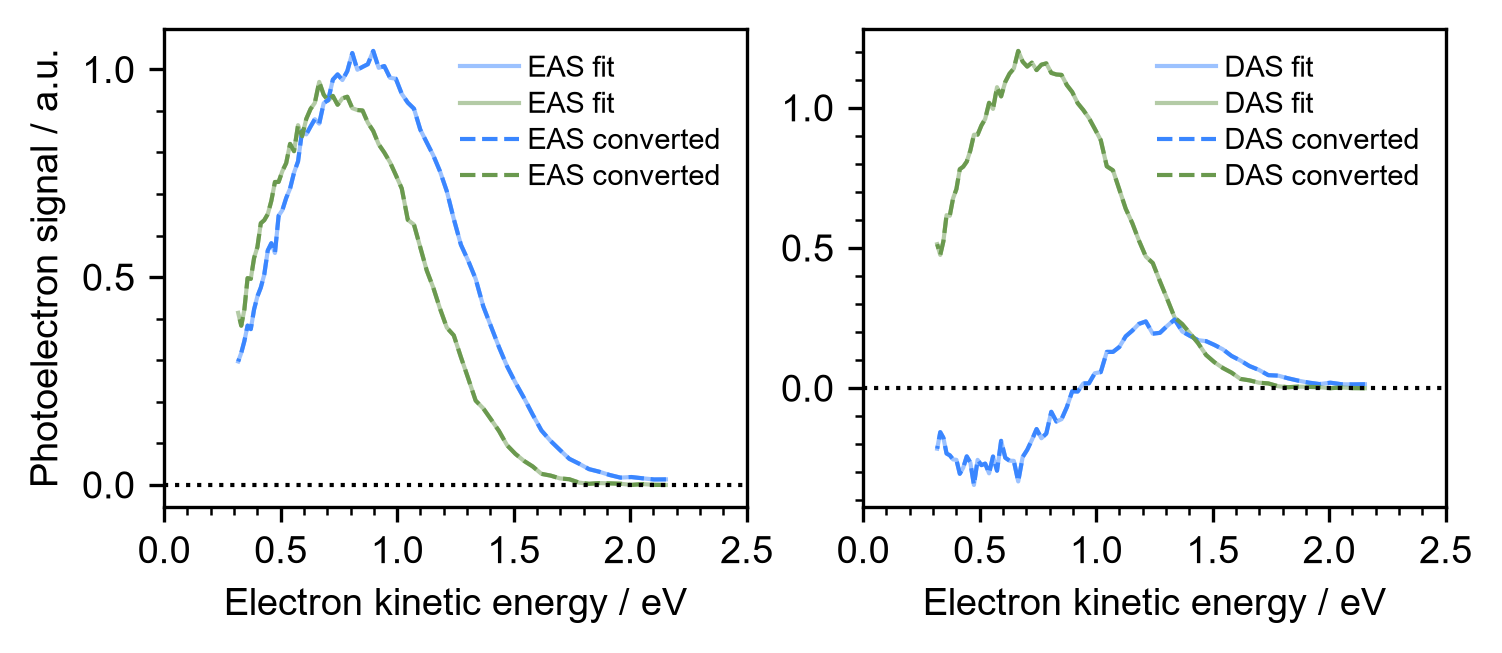

In [19]:
#Deriving DAS from EAS
fig,(ax0,ax1) = plt.subplots(1,2)
fig.set_size_inches(thesisWid,thesisWid/2*0.75)

#EAS
ax0.plot(energies,A1s_EAS,blue,alpha=.5,label='EAS fit')
ax0.plot(energies,A2s_EAS,green,alpha=.5,label='EAS fit')

A1s_EAS_converted, A2s_EAS_converted = DAS_to_EAS(A1s_DAS,A2s_DAS,tau1,tau2)

ax0.plot(energies,A1s_EAS_converted,'--', c=blue,alpha=1,label='EAS converted')
ax0.plot(energies,A2s_EAS_converted,'--', c=green,alpha=1,label='EAS converted')

#DAS
ax1.plot(energies,A1s_DAS, c=blue,alpha=.5,label='DAS fit')
ax1.plot(energies,A2s_DAS, c=green,alpha=.5,label='DAS fit')

A1s_DAS_converted, A2s_DAS_converted = EAS_to_DAS(A1s_EAS,A2s_EAS,tau1,tau2)

ax1.plot(energies,A1s_DAS_converted,'--', c=blue,alpha=1,label='DAS converted')
ax1.plot(energies,A2s_DAS_converted,'--', c=green,alpha=1,label='DAS converted')


for ax in ax0,ax1:
    ax.hlines(0,0,5,'k',':')
    ax.set_xlim(0,2.5)
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(0.1))
        
    ax.set_xlabel("Electron kinetic energy / eV",)
    ax.legend()
ax0.set_ylabel("Photoelectron signal / a.u.")


### Combined EAS & DAS plot

Plot total counts with the integrated EAS and DAS traces. Plot the DAS and EAS

In [20]:
amps1 = A1s_DAS,A1s_EAS
amps2 = A2s_DAS,A2s_EAS
A1s_errors = A1s_err_DAS,A1s_err_EAS
A2s_errors = A2s_err_DAS,A2s_err_EAS


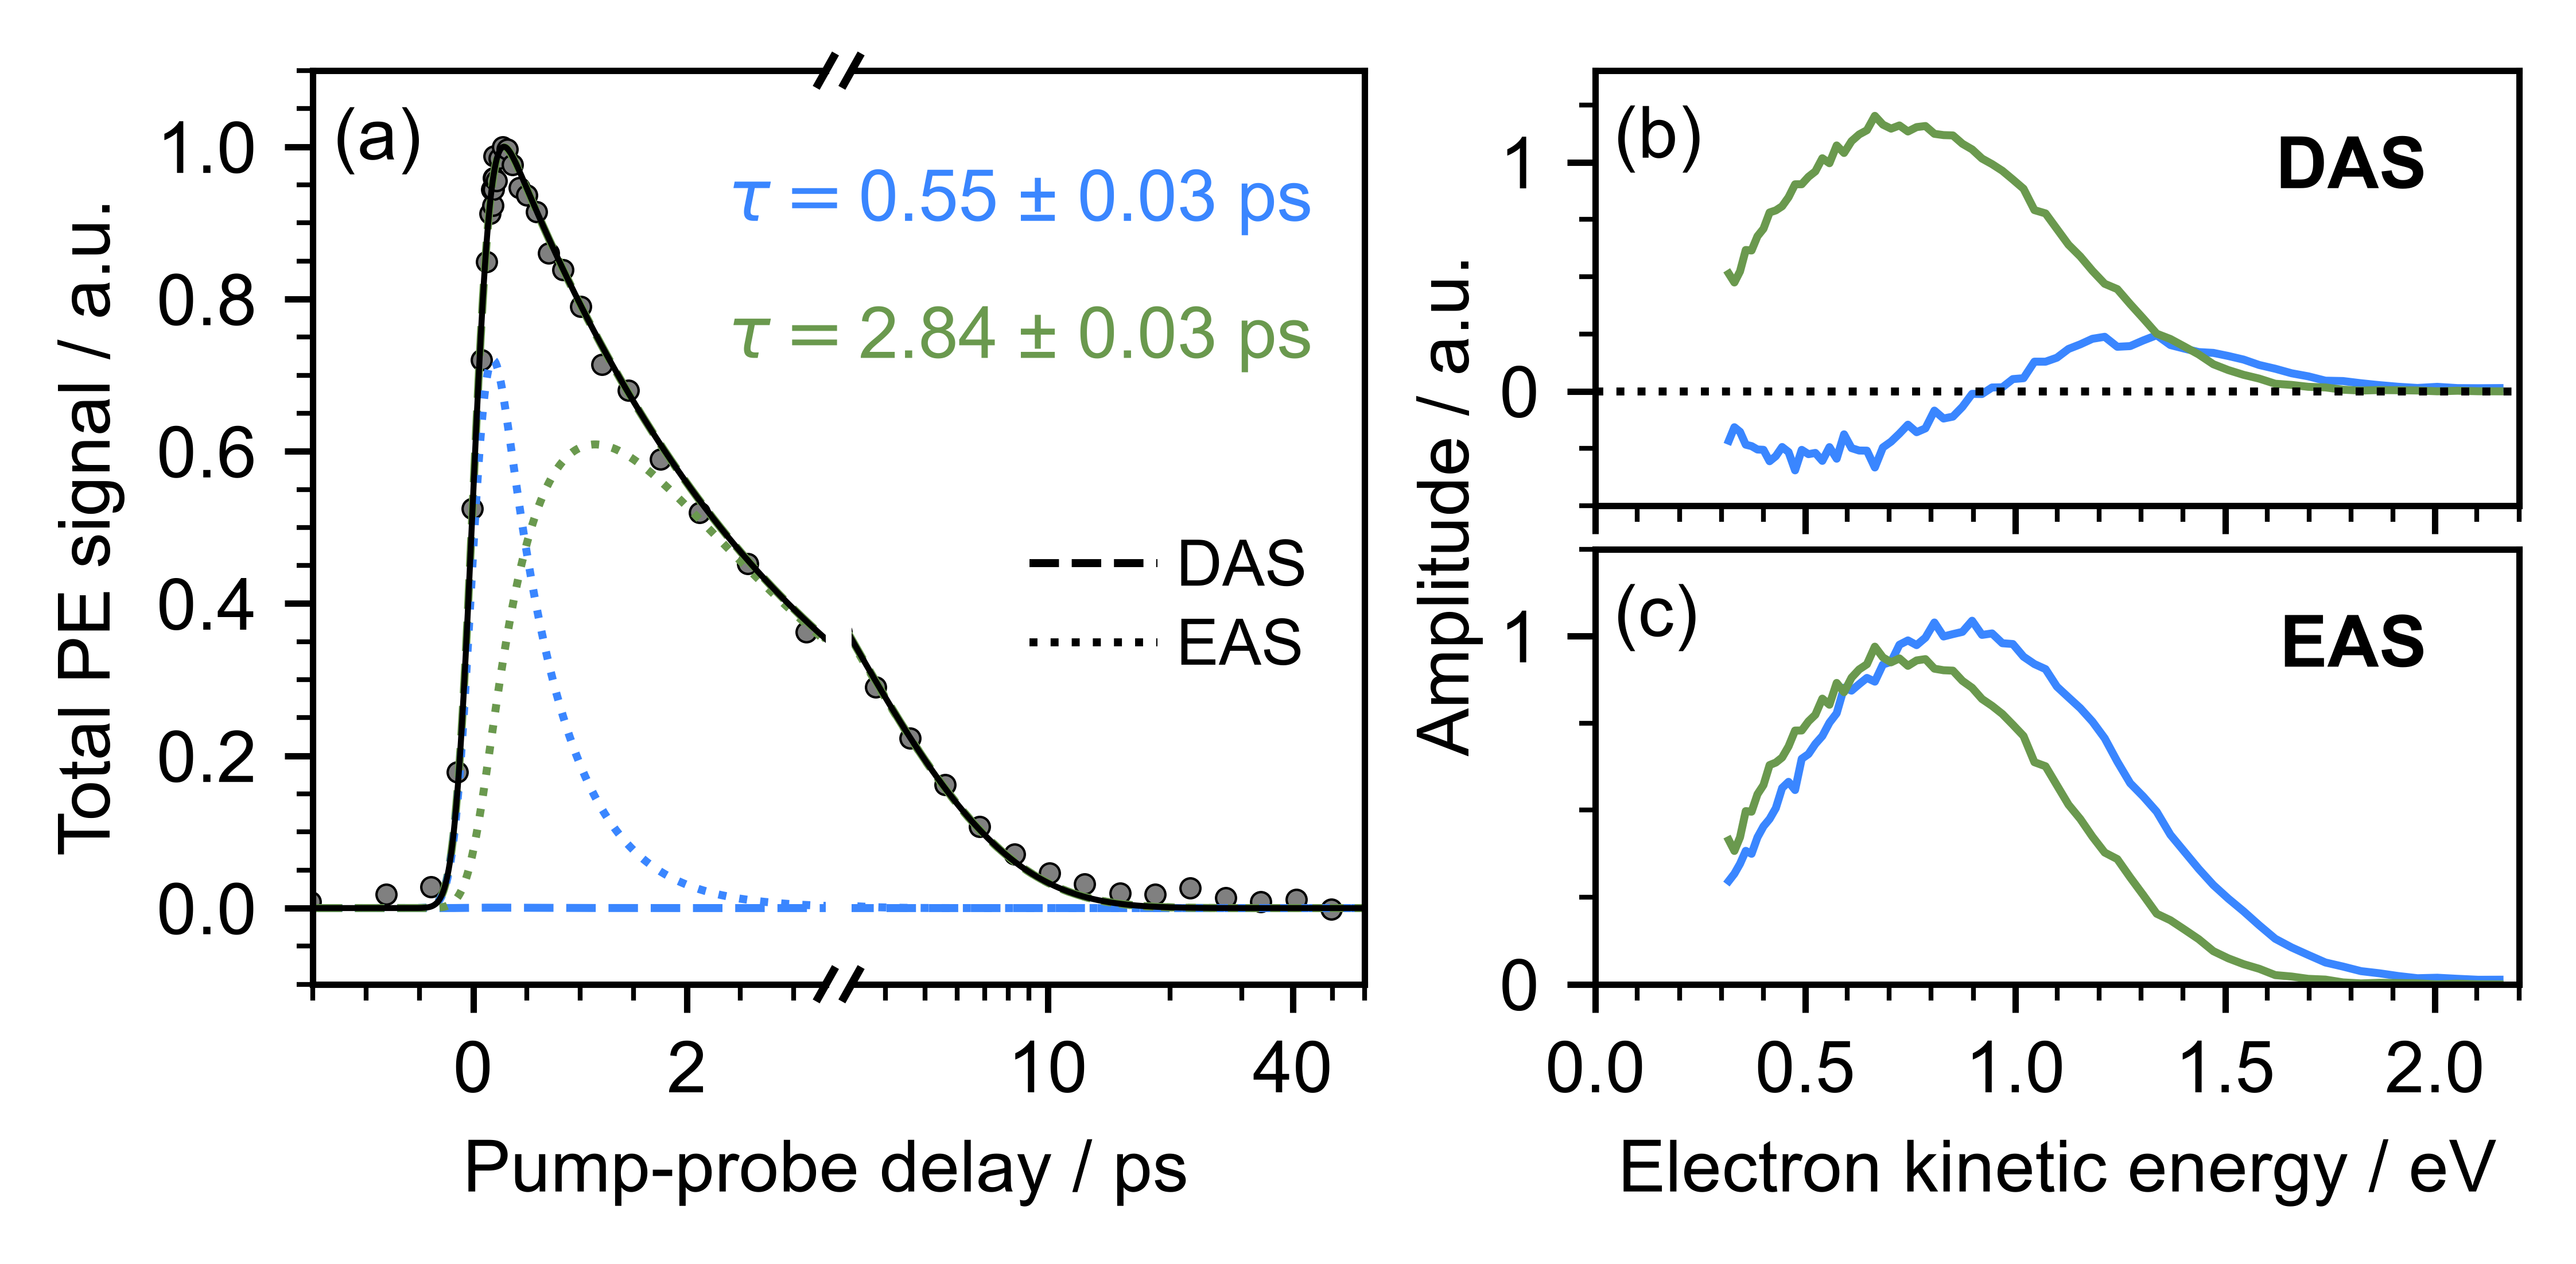

In [21]:
fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1,0.05,1,0.45,1.8],
                       height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax1b = fig.add_subplot(gs[:, 2])
ax2a = fig.add_subplot(gs[0, 4])
ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax1b,ax2a,ax2b

ts = np.arange(-5,100,.01)
#### Total counts
#Must integrate
trace = -np.trapezoid(subtracted_rebinned,axis=1,x=energies_rebinned)
trace = -np.trapezoid(subtracted_rebinned[:,mask],axis=1,x=energies_rebinned[mask])
trace /= max(trace)


#Formatting trace plot
for ax in axes[:2]:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.1,1.1)
    
ax1.set_xlim(-1.5,3.299)

ax1b.set_xscale('log')
ax1b.set_xlim(ax1.get_xlim()[1],60)
ax1b.set_xticks((10,40))
ax1b.set_xticklabels([f"{t}" for t in (10,40)])
ax1b.xaxis.set_minor_formatter(NullFormatter())

ax1b.set_yticklabels([])
ax1b.set_yticks([])

ax1.set_ylabel("Total PE signal / a.u.")
ax1.set_xlabel("Pump-probe delay / ps",x=1)


ax1.spines['right'].set_visible(False)
ax1b.spines['left'].set_visible(False)
    
ax1.yaxis.set_major_locator(MultipleLocator(.2))
ax1.yaxis.set_minor_locator(MultipleLocator(.05))

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((ax1,),(ax1b,)):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal



#DAS
flat_ts = np.tile(ts,traces.shape[1])
#Integrated total fit
sum_DAS = DAS_mod.global_fit(flat_ts,*params_DAS,delays_length=len(ts)).reshape(traces.shape[1],len(ts))
sum_DAS = -np.trapezoid(sum_DAS,axis=0,x=energies_rebinned[mask])
total_DAS = max(sum_DAS)
#Integrate monoexponentials
params_DAS1 = np.copy(params_DAS)
params_DAS1[3::2] = 0
sum_DAS1 = DAS_mod.global_fit(flat_ts,*params_DAS1,delays_length=len(ts)).reshape(traces.shape[1],len(ts))
sum_DAS1 = -np.trapezoid(sum_DAS1,axis=0,x=energies_rebinned[mask])

#Integrate monoexponentials
params_DAS2 = np.copy(params_DAS)
params_DAS2[2::2] = 0
sum_DAS2 = DAS_mod.global_fit(flat_ts,*params_DAS2,delays_length=len(ts)).reshape(traces.shape[1],len(ts))
sum_DAS2 = -np.trapezoid(sum_DAS2,axis=0,x=energies_rebinned[mask])

for ax in ax1,ax1b:
    ax.plot(delays,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)

    ax.plot(ts,sum_DAS1/total_DAS,'--',c=blue)
    ax.plot(ts,sum_DAS2/total_DAS,'--',c=green)
    ax.plot(ts,sum_DAS/total_DAS,'k',lw=.75,zorder=10)
    ax.plot(-10,-10,'k--',label="DAS")

#EAS

flat_ts = np.tile(ts,traces.shape[1])
#Integrated total fit
sum_EAS = EAS_mod.global_fit(flat_ts,*params_EAS,delays_length=len(ts)).reshape(traces.shape[1],len(ts))
sum_EAS = -np.trapezoid(sum_EAS,axis=0,x=energies_rebinned[mask])
total_EAS = max(sum_DAS)

#Integrate monoexponentials
params_EAS1 = np.copy(params_EAS)
params_EAS1[3::2] = 0
sum_EAS1 = EAS_mod.global_fit(flat_ts,*params_EAS1,delays_length=len(ts)).reshape(traces.shape[1],len(ts))
sum_EAS1 = -np.trapezoid(sum_EAS1,axis=0,x=energies_rebinned[mask])
#Integrate monoexponentials
params_EAS2 = np.copy(params_EAS)
params_EAS2[2::2] = 0
sum_EAS2 = EAS_mod.global_fit(flat_ts,*params_EAS2,delays_length=len(ts)).reshape(traces.shape[1],len(ts))
sum_EAS2 = -np.trapezoid(sum_EAS2,axis=0,x=energies_rebinned[mask])


for ax in ax1,ax1b:
    ax.plot(ts,sum_EAS1/total_EAS,':',c=blue)
    ax.plot(ts,sum_EAS2/total_EAS,':',c=green)
    ax.plot(-10,-10,'k:',label="EAS")
    
    
# Plotting EAS/DAS
for ax, A1s, A2s,A1s_err,A2s_err,fmt in zip((ax2a,ax2b),amps1,amps2,A1s_errors,A2s_errors,('--',':')):
    ax.plot(energies_rebinned[mask],A1s,'-',c=blue,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
    ax.plot(energies_rebinned[mask],A2s,'-',c=green,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

# Formatting EAS/DAS plots
for ax2 in ax2a,ax2b:
    ax2.set_xlim(0,2.2)
    # ax2.set_yticklabels([])
    ax2.yaxis.set_major_locator(MultipleLocator(1))
    ax2.yaxis.set_minor_locator(MultipleLocator(0.25))

    ax2.xaxis.set_major_locator(MultipleLocator(.5))
    ax2.xaxis.set_minor_locator(MultipleLocator(0.1))
ax2a.hlines(0,0,5,'k',':')
    
ax2a.set_ylabel("Amplitude / a.u.",y=0,labelpad=2)
ax2a.set_xticklabels([])
ax2b.set_xlabel("Electron kinetic energy / eV",)

ax2a.set_ylim(-.5,1.4)
ax2b.set_ylim(0,1.25)


ax2a.text(.9,.85,"DAS",ha='right',weight='bold',va='top',transform = ax2a.transAxes)
ax2b.text(.9,.85,"EAS",ha='right',weight='bold',va='top',transform = ax2b.transAxes)

ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1b.text(.9,.75,f"$\\tau =${taus_DAS[0]:.2f} ± {tau_errs_DAS[0]:.2f} ps\n",ha='right',c=blue,transform=ax1b.transAxes)
ax1b.text(.9,.6,f"$\\tau =${taus_DAS[1]:.2f} ± {tau_errs_DAS[1]:.2f} ps\n",ha='right',c=green,transform=ax1b.transAxes)

# Axis labels
ax1.text(.04,.96,f"({'a'})", va = "top",ha = "left",transform = ax1.transAxes)
ax2a.text(.02,.92,f"({'b'})", va = "top",ha = "left",transform = ax2a.transAxes)
ax2b.text(.02,.92,f"({'c'})", va = "top",ha = "left",transform = ax2b.transAxes)

fig.align_xlabels([ax1,ax1b,ax2b])



### Decaying retrieved gaussians

In [22]:
from scipy.special import erf


#### Load data rebinned onto grid

In [23]:
# Load data to fit
loaddata = np.loadtxt("data/out/LJscatterGridData.csv",delimiter=',')

energies_grid = loaddata[0,1:]
delays_grid = loaddata[1:,0]
subtracted_grid = loaddata [1:,1:]

#### Load basis sets for retrieval

In [24]:
#Load retrieval functions
h5path = r"bases/"

fileDic = {
    "a": 0.0,
    "b": 0.1,
    "c": 0.2,
    "d": 0.3,
    "e": 0.5,
    "f": 0.8,
    "g": 1.0,
    "h": 1.5,
    "i": 2.0,
}
concAmps = [0.0,0.1,0.2,0.5,1.0,2.0,2.75,3.0,4.0,5.0,10.0,20.0,50.0,100.0]
concAmps = [0.0,0.1,0.2,0.5,1.0,2.0,         4.6,5.0,10.0,20.0,50.0,100.0]
E0s = list(fileDic.values())
crossSectionSets = ['1b','2','4','5']

#Guide for indices of basisSets (E0 amp)
indexGuide = []
for E0 in fileDic.values():
    indices = []
    for amp in concAmps:
        indices.append((E0, amp))
    indexGuide.append(indices)
indexGuide = np.array(indexGuide)

print("Loading basis sets...")
# Here I keep it open because it is very big file
h5File = h5py.File(h5path+'basisSets_pCE_2026.hdf5', 'r')
allBasisSets = h5File['allBasisSets']
allBasisSetsUnnorm = h5File['allBasisSetsUnnorm']
print("Basis sets loaded")

allBasisSets

Loading basis sets...
Basis sets loaded


<HDF5 dataset "allBasisSets": shape (4, 9, 12, 500, 500), type "<f8">

#### The model

In [25]:
#Settings
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
num_surface = 5
num_bulk = 5
print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Surface gaussians: {num_surface}")
print('-'*8)
surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
surf_bas /= np.amax(surf_bas)


Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Surface gaussians: 5
--------


In [26]:
retr_model = km.RetrieveModel(0,
                 SIGMA,
                 delays_grid,
                 500,
                 # len(energies_grid),
                 surf_bas,
                 min(energies_grid))
len(energies)

70

#### Flatten delays + spectra

In [27]:
#Flatten energies
energies = np.arange(0.01,5.01,0.01)
flat_energies = np.tile(energies,len(delays_grid))


delays=None


In [28]:
# Rebin and flatten spectra
flat_spectra  =np.array(subtracted_grid).T.flatten()
flat_spectra.shape[0]/len(delays_grid)

469.0

In [29]:
len(delays_grid),len(energies_grid),flat_spectra.shape[0]

(47, 469, 22043)

In [30]:
retr_model.delays_length


47

#### Fit

In [31]:
p0 = [1,1.,.7,
      1,0.8,.7,
     0.5,2.8]

params,pcov = curve_fit(retr_model.global_fit,flat_energies,flat_spectra,
                        p0 = p0,bounds=(0,np.inf),)
perrs = np.sqrt(np.diag(pcov))
params,perrs

(array([0.65601782, 0.98988242, 0.78526199, 0.69151317, 0.84298821,
        0.7044953 , 0.58852086, 2.80744987]),
 array([0.00161045, 0.00160217, 0.0022518 , 0.00300116, 0.00163536,
        0.00315254, 0.01630526, 0.01449924]))

In [32]:
print(f"G1: eKE = {params[1]:.4f}, FWHM = {params[2]:.4f}, eBE = {1239.8/266.67- params[1]:.4f}, tau = {params[6]:.4f} ps")
print(f"G2: eKE = {params[4]:.4f}, FWHM = {params[5]:.4f}, eBE = {1239.8/266.67- params[4]:.4f}, tau = {params[7]:.4f} ps")


G1: eKE = 0.9899, FWHM = 0.7853, eBE = 3.6593, tau = 0.5885 ps
G2: eKE = 0.8430, FWHM = 0.7045, eBE = 3.8062, tau = 2.8074 ps


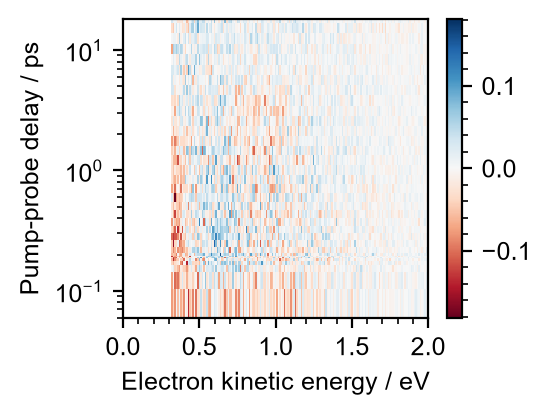

In [33]:
fig,ax = plt.subplots()
fig.set_dpi(200)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

# energies_grid = energies[energies>=min_eKE]


im0 = ax.pcolormesh(energies_grid,
                    delays_grid,
                    flat_spectra.reshape(subtracted_grid.shape[::-1]).T-
                    retr_model.global_fit(flat_energies,*params).reshape(subtracted_grid.shape[::-1]).T,
                    cmap='RdBu',
                    # shading='gouraud',
                    norm = mcolors.CenteredNorm()
                   )
ax.set_xlim(0,2)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
cbar = plt.colorbar(im0)
cbar.ax.yaxis.set_major_locator(MultipleLocator(.1))
cbar.ax.yaxis.set_minor_locator(MultipleLocator(.02))


#### Plot retrieved

[0.656, 0.9899, 0.7853, 0.6915, 0.843, 0.7045, 0.5885, 2.8074]
[0.0016, 0.0016, 0.0023, 0.003, 0.0016, 0.0032, 0.0163, 0.0145]
[7.2, 7.35]
[3.6593, 3.8062]
0.9486700304141845


C:\Users\edoar\AppData\Local\Temp\ipykernel_27516\2569240108.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


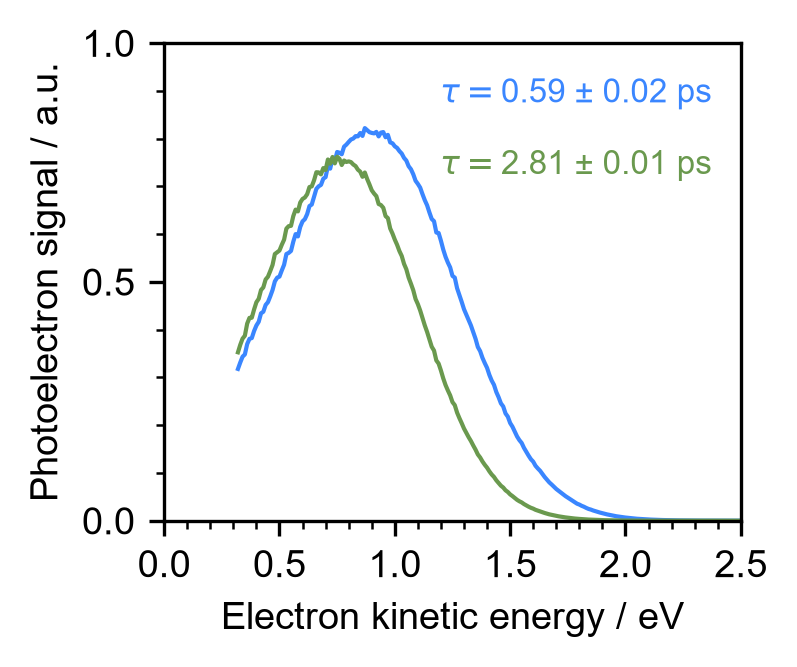

In [34]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)
tau1,tau2 = params[-2:]
tau1_err,tau2_err = perrs[-2:]

# ax.plot(energies,multiple_gaussians(energies,*params[:3]),c=blue,alpha=.5,label=f"$\\tau_1=${params[-2]:.2f}")
ax.plot(energies_grid,retr_model.retrieval_function(energies,*params[:3],0,0,1),c=blue)

# ax.plot(energies,multiple_gaussians(energies,*params[3:6]),c=green,alpha=.5,label=f"$\\tau_2=${params[-1]:.2f}")
ax.plot(energies_grid,retr_model.retrieval_function(energies,*params[3:6],0,0,1),c=green)

print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perrs])
print([float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}") for p in params[1:6:3]])
print([float(f"{1239.8/266.67 - p:.4f}") for p in params[1:6:3]])


ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

ax.set_xlim(0,2.5)
ax.set_ylim(0,1.)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")
plt.legend()
print(params[0]/params[3])

In [35]:
print(f"Ratio of blue and green peak area: {((params[0]*params[2])/(params[3]*params[5])):.2f}")

Ratio of blue and green peak area: 1.06


#### Plot combined fit trace+EAS plot

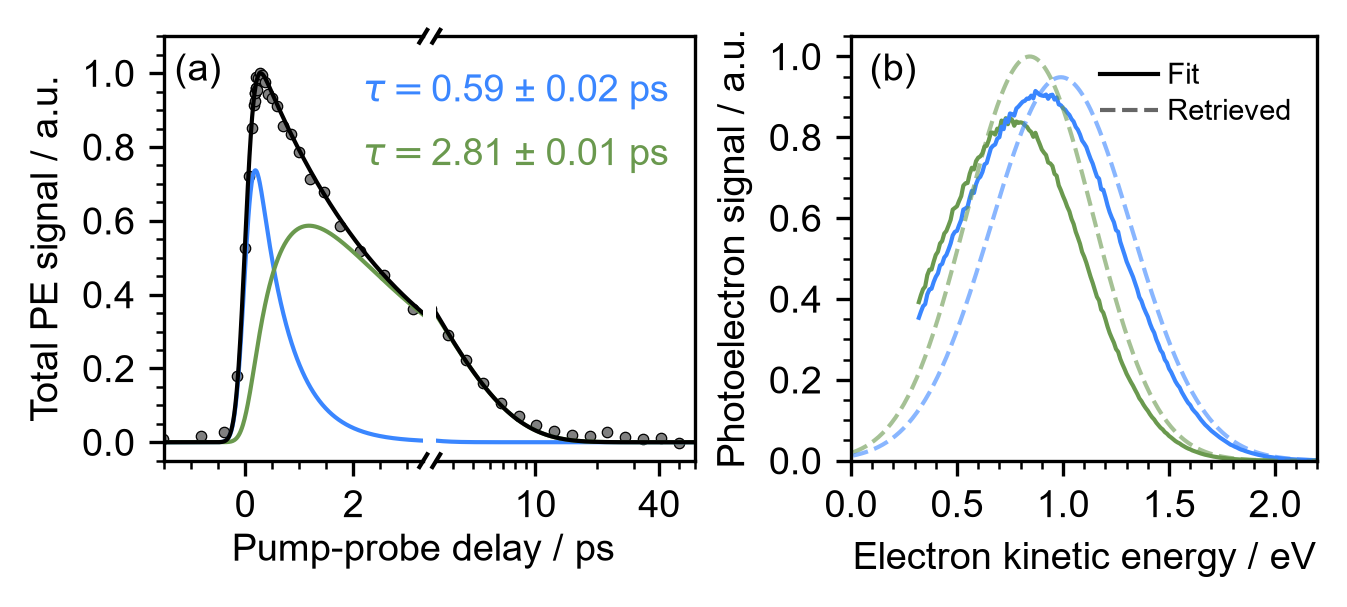

In [36]:
# To make it less verbose
A_model = retr_model.A_model
B_model = retr_model.B_model
retrieval_function = retr_model.retrieval_function

fig = plt.figure()
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.9,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1,0.05,1,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax1b = fig.add_subplot(gs[:, 2])
ax2 = fig.add_subplot(gs[:, 4])

axes = ax1,ax1b,ax2,

ts = np.arange(-5,100,.01)


#### Total total retrieved spectra
B1 = params[0]*params[2]
B2 = params[3]*params[5]
total_sig = B1*A_model(ts,1,tau1,SIGMA) + B2*B_model(ts,1,tau1,tau2,SIGMA)
total_norm = np.max(total_sig)
  
    
#### Total counts and total scattered spectra
total_sig = ( np.sum(retrieval_function(energies,*params[:3], 0,0,1))*A_model(ts,1,tau1,SIGMA) 
            + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,SIGMA) )
total_norm = np.max(total_sig)


#Plot total and individual components
for ax in ax1, ax1b:
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,SIGMA)/total_norm,
            c=blue)
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,SIGMA)/total_norm,
            c=green)
    ax.plot(ts,total_sig/total_norm,'k')


#This is equivalent to summing all the counts of the measured 
trace = -np.trapezoid(subtracted_rebinned,axis=1,x=energies_rebinned)
trace /= max(trace)
for ax in ax1,ax1b:
    ax.plot(delays_grid,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)


#Formatting trace
for ax in axes[:2]:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.05,1.1)
    
ax1.set_xlim(-1.5,3.299)

ax1b.set_xscale('log')
ax1b.set_xlim(ax1.get_xlim()[1],60)
ax1b.set_xticks((10,40))
ax1b.set_xticklabels([f"{t}" for t in (10,40)])

ax1b.set_yticklabels([])
ax1b.set_yticks([])

ax1.set_ylabel("Total PE signal / a.u.")
ax1.set_xlabel("Pump-probe delay / ps",x=1,labelpad=2)


ax1.spines['right'].set_visible(False)
ax1b.spines['left'].set_visible(False)
    
ax1.yaxis.set_major_locator(MultipleLocator(.2))
ax1.yaxis.set_minor_locator(MultipleLocator(.05))
ax1b.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((ax1,),(ax1b,)):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal
    


#Fit and retrieved EAS
#Normalisation to 1
norm = params[3] *1.3 # green gaussian max
# Fit EAS
ax2.plot(energies_grid,retrieval_function(energies,*params[3:6],0,0,1)/norm,c=green)
ax2.plot(energies_grid,retrieval_function(energies,*params[:3],0,0,1)/norm,c=blue)
# Retrieved EAS
#change norm for better clarity (absolute height is meaningless!)
norm = params[3] *1 # green gaussian max

# ax2.plot(energies_grid,multiple_gaussians(energies_grid,*params[3:6])/norm,c=green,alpha=.6)
# ax2.plot(energies_grid,multiple_gaussians(energies_grid,*params[:3])/norm,c=blue,alpha=.6)
# ax2.plot(energies_grid,multiple_gaussians(energies_grid,*params[3:6])/norm,'--',c=green,alpha=.6)
# ax2.plot(energies_grid,multiple_gaussians(energies_grid,*params[:3])/norm,'--',c=blue,alpha=.6)
ax2.plot(energies,multiple_gaussians(energies,*params[3:6])/norm,'--',c=green,alpha=.6)
ax2.plot(energies,multiple_gaussians(energies,*params[:3])/norm,'--',c=blue,alpha=.6)
#Legend
ax2.plot(-1,-1,c='k', label="Fit")
ax2.plot(-1,-1,'--',c='k', alpha=.6,label="Retrieved")

#True EAS
# ax2.plot(energies_DAS,A1s_EAS/1.5,'-',c='k',alpha=.5,)
# ax2.plot(energies_DAS,A2s_EAS/1.5,'-',c='k',alpha=.5,)

#Axes formatting
ax2.set_xlim(0,2.2)
# ax2.set_yticklabels([])
ax2.yaxis.set_major_locator(MultipleLocator(.2))
ax2.yaxis.set_minor_locator(MultipleLocator(0.05))

ax2.xaxis.set_major_locator(MultipleLocator(.5))
ax2.xaxis.set_minor_locator(MultipleLocator(0.1))
    

ax2.set_ylabel("Photoelectron signal / a.u.",)#labelpad=2)
ax2.set_xlabel("Electron kinetic energy / eV",)

ax2.set_ylim(0,1.05)

ax2.legend()

# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1b.text(.9,.75,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,transform=ax1b.transAxes)
ax1b.text(.9,.6,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,transform=ax1b.transAxes)

for ax,indx in zip((ax1,ax2),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)

fig.align_xlabels([ax1,ax1b,ax2])